### Package versions

Run the cell below to record the exact package versions used to generate the results in this notebook.


In [1]:
# --- Environment / package versions (added for reproducibility) ---
import sys
try:
    from importlib.metadata import version, PackageNotFoundError
except ImportError:  # Python < 3.8
    from importlib_metadata import version, PackageNotFoundError
print("Python:", sys.version.split()[0])
for _pkg in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "seaborn", "gseapy", "pyliftover", "openpyxl", "requests", "pyBigWig", "pyreadr", "adjustText", "pypdf"]:
    try:
        print(f"{_pkg}: {version(_pkg)}")
    except PackageNotFoundError:
        pass


Python: 3.10.12
numpy: 2.2.6
pandas: 2.3.3
scipy: 1.15.3
statsmodels: 0.14.6
matplotlib: 3.10.9
seaborn: 0.13.2
gseapy: 1.3.1
openpyxl: 3.1.5
requests: 2.34.2
pyreadr: 0.5.6
adjustText: 1.4.0
pypdf: 6.13.1


# SLC38A4 expression in Huh7.5 cells exposed to SAH patient plasma and mediators

**Input:** `Fig2D_SLC38A4_SAH_mediators_data.xlsx`  
(generated by `Fig2D_SLC38A4_SAH_mediators.ipynb`)

Values are normalised to the control well mean: fold change = treated / mean(ctrl) − 1.

> **Control pooling:** for the five mediator conditions (IL-1β, TGFβ1, Dex, Dex+IL-1β, Dex+TGFβ1) TGFβ1 ctrl wells and Dex ctrl wells are fully independent from each other and from the IL-1β and Dex-combination ctrl groups on the same plate (confirmed by exact-value matching in the Prism table). These six wells are pooled as a common control (n = 6) for all five conditions.  
SAH plasma and EtOH are from separate experiments and retain their own ctrl (n = 4).  
**Statistics:** Welch's unpaired t-test (ctrl vs treated, on relative expression (linear scale)), uncorrected.

## 1 · Imports and style

In [2]:
from itertools import combinations

import numpy as np
import pandas as pd
from scipy import stats

import matplotlib.pyplot as plt

np.random.seed(42)  # reproducible jitter

plt.rcParams.update({
    'font.family':          'sans-serif',
    'font.sans-serif':      ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size':            10,
    'axes.linewidth':       1.0,
    'axes.spines.top':      False,
    'axes.spines.right':    False,
    'xtick.major.width':    1.0,
    'ytick.major.width':    1.0,
    'xtick.major.size':     4,
    'ytick.major.size':     4,
    'savefig.dpi':          300,
    'pdf.fonttype':         42,   # editable text in Illustrator / Inkscape
    'ps.fonttype':          42,
})

## 2 · Load data

In [3]:
XLSX_PATH = 'Fig2D_SLC38A4_SAH_mediators_data.xlsx'
df_raw = pd.read_excel(XLSX_PATH, sheet_name='Raw expression')

GROUPS = [
    ('SAH plasma',  'SAH\nplasma'),
    ('EtOH',        'EtOH'),
    ('IL-1β',        'IL-1β'),
    ('TGFβ1',         'TGFβ1'),
    ('Dex',         'Dex'),
    ('Dex+IL-1β',    'Dex+\nIL-1β'),
    ('Dex+TGFβ1',    'Dex+\nTGFβ1'),
]
keys   = [g[0] for g in GROUPS]
labels = [g[1] for g in GROUPS]

# TGFβ1 and Dex ctrl wells are fully independent on the same plate.
# Pool them as a common n=6 reference for all five mediator conditions.
# SAH plasma and EtOH are from separate experiments — own ctrl retained.
MEDIATOR_CTRL = [1.25, 0.95, 0.80, 0.93, 1.06, 1.01]  # TGFβ1 ctrl + Dex ctrl

ctrl    = {}
treated = {}
raw     = {}

for k, _ in GROUPS:
    sub = df_raw[df_raw['treatment'] == k]
    t = [float(v) for v in sub['treated_expression'].dropna()]
    if k in ('SAH plasma', 'EtOH'):
        c = [float(v) for v in sub['ctrl_expression'].dropna()]
    else:
        c = MEDIATOR_CTRL
    ctrl[k]    = c
    treated[k] = t
    raw[k]     = [v / float(np.mean(c)) - 1 for v in t]

def _sem(x):
    return x.std(ddof=1) / np.sqrt(len(x))

df_vals = pd.DataFrame(
    [{'key': k, 'label': lbl, 'value': v}
     for k, lbl in GROUPS
     for v in raw[k]]
)

summary = (
    df_vals.groupby('key', sort=False)['value']
    .agg(n='count', mean='mean', sem=_sem, minimum='min', maximum='max')
    .loc[keys]
    .reset_index()
)
summary.insert(1, 'label', [lbl.replace('\n', ' ') for lbl in labels])
summary.insert(2, 'n_ctrl', [len(ctrl[k]) for k in keys])

print(summary[['label', 'n_ctrl', 'n', 'mean', 'sem', 'minimum', 'maximum']]
      .rename(columns={'n': 'n_treated'})
      .to_string(index=False, float_format=lambda x: f'{x:.4f}'))

     label  n_ctrl  n_treated    mean    sem  minimum  maximum
SAH plasma       4          4 -0.5100 0.0964  -0.7900  -0.3500
      EtOH       4          4 -0.4730 0.0111  -0.4963  -0.4454
     IL-1β       6          4 -0.7325 0.0413  -0.7900  -0.6100
     TGFβ1       6          3 -0.4433 0.0713  -0.5800  -0.3400
       Dex       6          3  0.3333 0.0448   0.2700   0.4200
Dex+ IL-1β       6          3  0.3767 0.0367   0.3400   0.4500
Dex+ TGFβ1       6          3 -0.0067 0.0935  -0.1100   0.1800


## 3 · Statistical analysis

Welch's unpaired t-test (ctrl vs treated, on relative expression (linear scale)) per condition, uncorrected. Mediator conditions use the pooled n = 6 ctrl (TGFβ1 + Dex wells). SAH plasma and EtOH use their own n = 4 ctrl.

In [4]:
# Welch's unpaired t-test: ctrl wells vs treated wells (linear relative expression).
rows = []
for k, lbl in GROUPS:
    c  = np.array(ctrl[k])
    t  = np.array(treated[k])
    fc = np.array(raw[k])
    t_stat, p_val = stats.ttest_ind(c, t, equal_var=False)
    rows.append({
        'Group':              lbl.replace('\n', ' '),
        'n (ctrl)':           len(c),
        'n (treated)':        len(t),
        'Mean ctrl':          round(float(c.mean()), 4),
        'Mean treated':       round(float(t.mean()), 4),
        'Mean fold change':   round(float(fc.mean()), 4),
        'SEM fold change':    round(float(fc.std(ddof=1) / np.sqrt(len(fc))), 4),
        't':                  round(float(t_stat), 3),
        'p':                  float(p_val),
    })

stats_df = pd.DataFrame(rows)
stats_df['Sig.'] = stats_df['p'].apply(
    lambda p: '****' if p < 0.0001 else '***' if p < 0.001
              else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
)

display_df = stats_df.copy()
display_df['p'] = display_df['p'].apply(
    lambda p: f'{p:.2e}' if p < 0.0001 else f'{p:.4f}'
)
display(display_df)

,Group,n (ctrl),n (treated),Mean ctrl,Mean treated,Mean fold change,SEM fold change,t,p,Sig.
0,SAH plasma,4,4,1.0,0.4900,-0.5100,0.0964,4.070,0.0070,**
1,EtOH,4,4,1.0,0.5270,-0.4730,0.0111,4.860,0.0157,*
2,IL-1β,6,4,1.0,0.2675,-0.7325,0.0413,9.883,1.05e-05,****
3,TGFβ1,6,3,1.0,0.5567,-0.4433,0.0713,4.709,0.0053,**
4,Dex,6,3,1.0,1.3333,0.3333,0.0448,-4.378,0.0034,**
5,Dex+ IL-1β,6,3,1.0,1.3767,0.3767,0.0367,-5.258,0.0012,**
6,Dex+ TGFβ1,6,3,1.0,0.9933,-0.0067,0.0935,0.060,0.9555,ns


## 4 · Figure 2D

Bar chart (mean ± SEM of fold changes) with individual treated data points overlaid. Dashed line at y = 0 marks the control baseline. Exact p-values from Welch's t-test (ctrl vs treated) are shown below each bar. Y-axis fixed to −1 – 0.6.

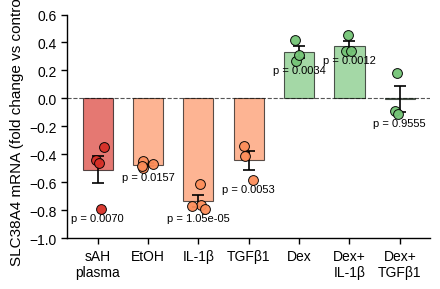

Saved: Fig2D_SLC38A4_SAH_mediators.pdf


In [5]:
# Colours indexed by group position (order matches GROUPS definition)
COLORS = [
    '#D73027',  # SAH plasma
    '#FC8D59',  # EtOH
    '#FC8D59',  # IL-1β
    '#FC8D59',  # TGFβ1
    '#74C476',  # Dex
    '#74C476',  # Dex+IL-1β
    '#74C476',  # Dex+TGFβ1
]

x = np.arange(len(keys))
fig, ax = plt.subplots(figsize=(4.5, 3))

# Reference line at 0 (no change from control)
ax.axhline(0, color='#555555', linewidth=0.8, linestyle='--', zorder=1)

y_bottoms = []

for xi, (key, lbl) in enumerate(zip(keys, labels)):
    vals = np.array(raw[key])
    mn   = vals.mean()
    se   = vals.std(ddof=1) / np.sqrt(len(vals)) if len(vals) > 1 else 0.0
    c    = COLORS[xi]

    ax.bar(xi, mn, width=0.6, color=c, alpha=0.65,
           edgecolor='black', linewidth=0.8, zorder=2)
    ax.errorbar(xi, mn, yerr=se,
                color='black', linewidth=1.2,
                capsize=4, capthick=1.2, zorder=3)
    jitter = np.random.uniform(-0.14, 0.14, size=len(vals))
    ax.scatter(xi + jitter, vals,
               color=c, edgecolors='black', linewidth=0.7,
               s=50, zorder=4, alpha=0.95)

    y_bottoms.append(min(mn - se, float(vals.min())))

# Exact p-value annotations placed below the lowest point of each bar
p_lookup = dict(zip(keys, stats_df['p'].values))

def fmt_p(p):
    if p < 0.0001:
        return f'p = {p:.2e}'
    return f'p = {p:.4f}'

for xi, key in enumerate(keys):
    ax.text(xi, y_bottoms[xi] - 0.03, fmt_p(p_lookup[key]),
            ha='center', va='top', fontsize=8, color='black')

ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10)
ax.set_ylabel('SLC38A4 mRNA (fold change vs control)', fontsize=11)
ax.set_xlim(-0.6, len(keys) - 0.4)
ax.set_ylim(-1, 0.6)

plt.tight_layout()
fig.savefig('Fig2D_SLC38A4_SAH_mediators.pdf', bbox_inches='tight')
plt.show()
print('Saved: Fig2D_SLC38A4_SAH_mediators.pdf')

## 5 · Supplementary data

Three sheets: individual values, summary statistics, and statistical tests.  
Exported to `Fig2D_SLC38A4_SAH_mediators_supplementary_data.xlsx`.

In [6]:
# ── Sheet 1: individual values ────────────────────────────────────────────
supp_vals = pd.DataFrame(
    [{'Treatment':                   lbl.replace('\n', ' '),
      'Replicate':                   i + 1,
      'Ctrl expression (well mean)': round(float(np.mean(ctrl[k])), 6),
      'Treated expression':          round(v_t, 6),
      'Fold change':                 round(v_fc, 6)}
     for k, lbl in GROUPS
     for i, (v_t, v_fc) in enumerate(zip(treated[k], raw[k]))]
)

# ── Sheet 2: summary statistics ──────────────────────────────────────────────
supp_summ = (
    summary[['label', 'n_ctrl', 'n', 'mean', 'sem', 'minimum', 'maximum']]
    .rename(columns={
        'label':   'Treatment',
        'n':       'n (treated)',
        'mean':    'Mean fold change',
        'sem':     'SEM',
        'minimum': 'Minimum',
        'maximum': 'Maximum',
    })
    .round(6)
)

# ── Sheet 3: statistical tests ────────────────────────────────────────────────
note = (
    '† Welch’s unpaired t-test comparing ctrl vs treated (linear relative expression). '
    'Each condition was tested independently; p-values are uncorrected.'
)

print('=== Individual values ===');  display(supp_vals)
print('\n=== Summary statistics ==='); display(supp_summ)
print('\n=== Statistical tests (Welch’s unpaired t-test) ==='); display(stats_df)
print(f'\n{note}')

out_path = 'Fig2D_SLC38A4_SAH_mediators_supplementary_data.xlsx'
with pd.ExcelWriter(out_path, engine='openpyxl') as writer:
    supp_vals.to_excel(writer,  sheet_name='Individual values',  index=False)
    supp_summ.to_excel(writer,  sheet_name='Summary statistics', index=False)
    stats_df.to_excel(writer,   sheet_name='Statistical tests',  index=False)
    ws = writer.sheets['Statistical tests']
    ws.cell(row=len(stats_df) + 3, column=1, value=note)

print(f'\nSaved: {out_path}')

=== Individual values ===


,Treatment,Replicate,Ctrl expression (well mean),Treated expression,Fold change
0,SAH plasma,1,1.0,0.560000,-0.440000
1,SAH plasma,2,1.0,0.650000,-0.350000
2,SAH plasma,3,1.0,0.210000,-0.790000
3,SAH plasma,4,1.0,0.540000,-0.460000
4,EtOH,1,1.0,0.554635,-0.445365
5,EtOH,2,1.0,0.503662,-0.496338
6,EtOH,3,1.0,0.515808,-0.484192
7,EtOH,4,1.0,0.533887,-0.466113
8,IL-1β,1,1.0,0.390000,-0.610000
9,IL-1β,2,1.0,0.240000,-0.760000



=== Summary statistics ===


,Treatment,n_ctrl,n (treated),Mean fold change,SEM,Minimum,Maximum
0,SAH plasma,4,4,-0.510000,0.096350,-0.790000,-0.350000
1,EtOH,4,4,-0.473002,0.011109,-0.496338,-0.445365
2,IL-1β,6,4,-0.732500,0.041307,-0.790000,-0.610000
3,TGFβ1,6,3,-0.443333,0.071259,-0.580000,-0.340000
4,Dex,6,3,0.333333,0.044845,0.270000,0.420000
5,Dex+ IL-1β,6,3,0.376667,0.036667,0.340000,0.450000
6,Dex+ TGFβ1,6,3,-0.006667,0.093512,-0.110000,0.180000



=== Statistical tests (Welch’s unpaired t-test) ===


,Group,n (ctrl),n (treated),Mean ctrl,Mean treated,Mean fold change,SEM fold change,t,p,Sig.
0,SAH plasma,4,4,1.0,0.4900,-0.5100,0.0964,4.070,0.007044,**
1,EtOH,4,4,1.0,0.5270,-0.4730,0.0111,4.860,0.015652,*
2,IL-1β,6,4,1.0,0.2675,-0.7325,0.0413,9.883,0.000010,****
3,TGFβ1,6,3,1.0,0.5567,-0.4433,0.0713,4.709,0.005334,**
4,Dex,6,3,1.0,1.3333,0.3333,0.0448,-4.378,0.003387,**
5,Dex+ IL-1β,6,3,1.0,1.3767,0.3767,0.0367,-5.258,0.001186,**
6,Dex+ TGFβ1,6,3,1.0,0.9933,-0.0067,0.0935,0.060,0.955494,ns



† Welch’s unpaired t-test comparing ctrl vs treated (linear relative expression). Each condition was tested independently; p-values are uncorrected.

Saved: Fig2D_SLC38A4_SAH_mediators_supplementary_data.xlsx
